In [3]:
# Install the required packages 
!pip install pandas numpy scikit-learn matplotlib seaborn joblib  mlflow

In [5]:
import pandas as pd
import numpy as np
import sklearn
import joblib
import matplotlib
import seaborn
import os
import mlflow

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import ( StandardScaler, OneHotEncoder)
from sklearn.pipeline import Pipeline 
from sklearn.metrics import recall_score, f1_score, precision_score, accuracy_score, classification_report,  confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

print("All packages imported successfully!")
print("Joblib version:", joblib.__version__)
print("Scikit-learn version:", sklearn.__version__)

All packages imported successfully!
Joblib version: 1.4.2
Scikit-learn version: 1.8.0


In [6]:
data_path = "../data/customer_churn(500).csv"
df = pd.read_csv(data_path)
df.head()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges,Contract,InternetService,SupportCalls,PaymentMethod,Churn
0,10001,56,1,35.17,35.17,Month-to-Month,Fiber Optic,6,Electronic Check,Yes
1,10002,69,58,51.17,3008.73,One Year,Fiber Optic,6,Mailed Check,No
2,10003,46,1,44.85,44.85,Month-to-Month,DSL,0,Credit Card,No
3,10004,32,34,94.39,3073.99,Month-to-Month,Fiber Optic,2,Credit Card,Yes
4,10005,60,48,23.35,968.56,Month-to-Month,DSL,1,Credit Card,No


In [7]:
import os
print(os.getcwd())

C:\Teju\ML_Flow_Project\notebooks


In [8]:
import os
print(os.listdir("../data"))

['.ipynb_checkpoints', 'customer_churn(500).csv']


In [9]:
# understanding the dataset 
df.isnull().sum()
print( df["Churn"].value_counts() )
print("----------")
print ( df["Churn"].value_counts(normalize=True) * 100 )


Churn
No     261
Yes    239
Name: count, dtype: int64
----------
Churn
No     52.2
Yes    47.8
Name: proportion, dtype: float64


In [10]:
target = "Churn"

# getting all columns except CustomerId and target 
features = [  c for c in df.columns  if c not in ["CustomerID", target]  ]

X = df[features]  #  return  only given columns values 
Y = df[target]     # return only churn column values 

print("Features:", features)
print("Target:", target)


Features: ['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService', 'SupportCalls', 'PaymentMethod']
Target: Churn


In [11]:
y = Y.map({
    "No": 0,
    "Yes": 1
})
print( X.head() )
print (y.head() )

   Age  Tenure  MonthlyCharges  TotalCharges        Contract InternetService  \
0   56       1           35.17         35.17  Month-to-Month     Fiber Optic   
1   69      58           51.17       3008.73        One Year     Fiber Optic   
2   46       1           44.85         44.85  Month-to-Month             DSL   
3   32      34           94.39       3073.99  Month-to-Month     Fiber Optic   
4   60      48           23.35        968.56  Month-to-Month             DSL   

   SupportCalls     PaymentMethod  
0             6  Electronic Check  
1             6      Mailed Check  
2             0       Credit Card  
3             2       Credit Card  
4             1       Credit Card  
0    1
1    0
2    0
3    1
4    0
Name: Churn, dtype: int64


In [12]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["str"]          # it will updated in future verions as  object
).columns.tolist()

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)



Numerical: ['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'SupportCalls']
Categorical: ['Contract', 'InternetService', 'PaymentMethod']


In [13]:
# Split Data -  training data (learning) and test data (evaluate)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Total records :", len(X))
print("Training data :", len(X_train))
print("Testing data  :", len(X_test))

Total records : 500
Training data : 400
Testing data  : 100


In [14]:
# Create preprocessing:   (for scaling numeric & string based data)
preprocessor = ColumnTransformer(
    transformers=[ 
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)


In [15]:
# Create the ML Model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("model is created successfully");


model is created successfully


In [16]:
# Now combine preprocessing + model:
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ]
)

pipeline.fit( X_train, y_train )
print("Now model trained")

Now model trained


In [17]:
#predict the result
y_pred = pipeline.predict(X_test)

# Check some predictions:
print(y_pred[:20])   #  returns first 20 items

[1 0 0 1 1 1 1 1 0 0 0 0 1 1 1 0 1 1 1 0]


In [18]:
#  Evaluate the Model  (Evaluation Metrics)
#  Note :   
#   y_test  =   actual predictions from test data
#   y_pred  =  predictions generated by trained model 
accuracy = accuracy_score(y_test,  y_pred )
precision = precision_score(y_test, y_pred )
recall = recall_score(y_test, y_pred )
f1 = f1_score(y_test, y_pred )

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


Accuracy : 0.79
Precision: 0.7872340425531915
Recall   : 0.7708333333333334
F1 Score : 0.7789473684210526


In [19]:
# Classification Report
print(    classification_report(  y_test,   y_pred  )  )
# In[29]:
# creating confusion matrix
cm = confusion_matrix(  y_test,   y_pred )
print(cm)

              precision    recall  f1-score   support

           0       0.79      0.81      0.80        52
           1       0.79      0.77      0.78        48

    accuracy                           0.79       100
   macro avg       0.79      0.79      0.79       100
weighted avg       0.79      0.79      0.79       100

[[42 10]
 [11 37]]


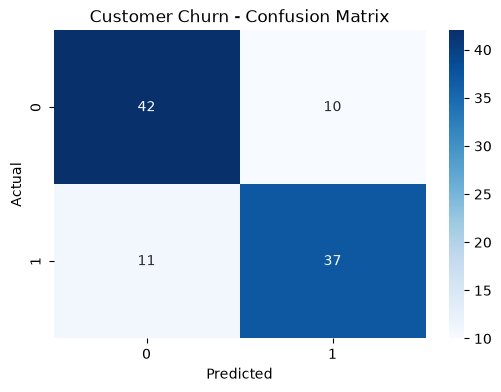

In [20]:
# import matplotlib.pyplot as plt

# matplotlib.pyplot is a sub-module of the Matplotlib library that provides a collection of functions to create and customize data visualizations in Python


plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Churn - Confusion Matrix")

plt.show()


Artifacts - Confusion matrix saved successfully..!


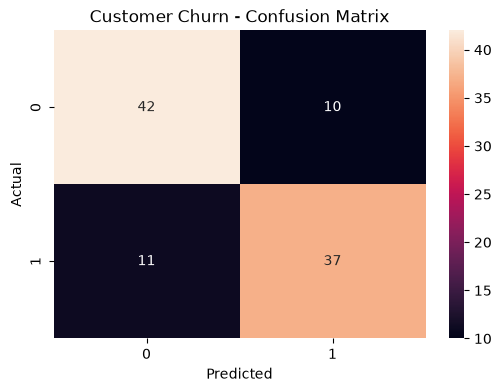

In [21]:
# save the confution matrix 
os.makedirs(
    "artifacts",
    exist_ok=True
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Churn - Confusion Matrix")

plt.savefig(
    "artifacts/confusion_matrix.png"
)


print("Artifacts - Confusion matrix saved successfully..!")


In [23]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Customer Churn Prediction")

with mlflow.start_run():
 # 1. Train Model
    pipeline.fit(  X_train,    y_train  )

    # 2. Prediction
    y_pred = pipeline.predict(     X_test   )

    # 3. Evaluation
    accuracy = accuracy_score( y_test,  y_pred )
    precision = precision_score(  y_test,     y_pred   )
    recall = recall_score(     y_test,      y_pred   )
    f1 = f1_score(y_test,      y_pred  )


    # 4. Log Parameters 
    mlflow.log_param( "model_type",  "Logistic Regression"  )
    mlflow.log_param(  "max_iter",  1000   )
    mlflow.log_param(  "test_size",   0.2   )


    # 5. Log Metrics 
    mlflow.log_metric( "accuracy",  accuracy  )
    mlflow.log_metric(     "precision",      precision  )
    mlflow.log_metric(     "recall",      recall  )
    mlflow.log_metric(      "f1_score",       f1  )


    # 6. Log Artifact
    mlflow.log_artifact("artifacts/confusion_matrix.png"  )

    # 7. Log Model 
    mlflow.sklearn.log_model(pipeline, name="customer_churn_model")
    print("MLflow Run Completed")

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)


MLflow Run Completed
Accuracy : 0.79
Precision: 0.7872340425531915
Recall   : 0.7708333333333334
F1 Score : 0.7789473684210526
🏃 View run stately-wasp-266 at: http://127.0.0.1:5000/#/experiments/1/runs/7d6a848ba4ed438e9d90851f864c0c9a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
